In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, auc
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import label_binarize

In [3]:
variant = 1

df = sns.load_dataset('iris')
X = df[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']]
y = df['species']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=variant)

In [4]:
rf = RandomForestClassifier(n_estimators=300, random_state=variant)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

print(classification_report(y_test, pred_rf))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [5]:
gb = GradientBoostingClassifier(random_state=variant)
gb.fit(X_train, y_train)
pred_gb = gb.predict(X_test)

print(classification_report(y_test, pred_gb))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



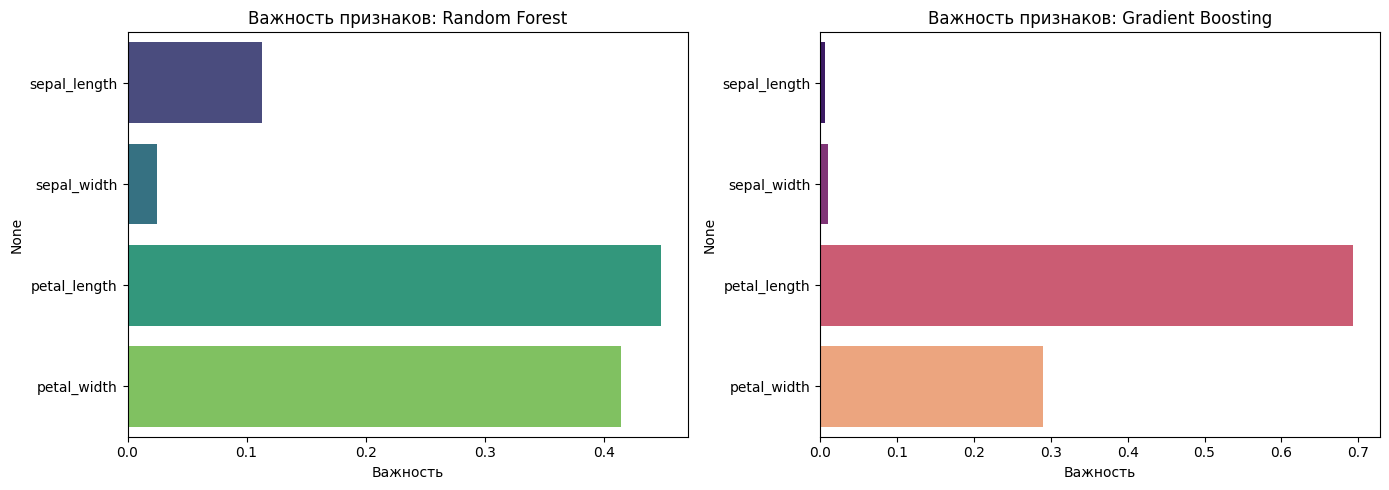

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

feature_names = X.columns
rf_importances = rf.feature_importances_
sns.barplot(x=rf_importances, y=feature_names, ax=axes[0], palette='viridis', hue=feature_names, legend=False)
axes[0].set_title('Важность признаков: Random Forest')
axes[0].set_xlabel('Важность')

gb_importances = gb.feature_importances_
sns.barplot(x=gb_importances, y=feature_names, ax=axes[1], palette='magma', hue=feature_names, legend=False)
axes[1].set_title('Важность признаков: Gradient Boosting')
axes[1].set_xlabel('Важность')

plt.tight_layout()
plt.show()

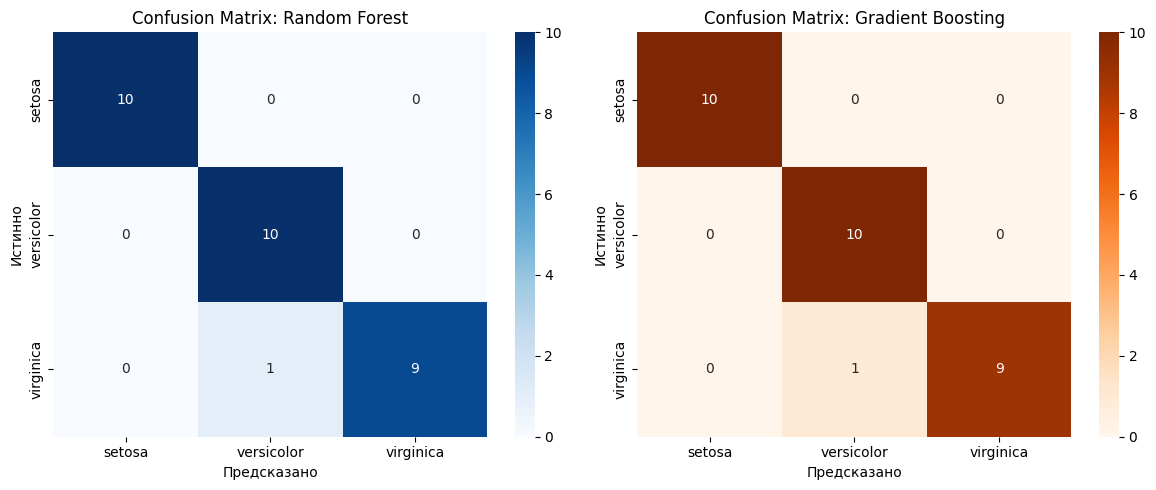

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf = confusion_matrix(y_test, pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=rf.classes_, yticklabels=rf.classes_)
axes[0].set_title('Confusion Matrix: Random Forest')
axes[0].set_xlabel('Предсказано')
axes[0].set_ylabel('Истинно')

cm_gb = confusion_matrix(y_test, pred_gb)
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Oranges', ax=axes[1],
            xticklabels=gb.classes_, yticklabels=gb.classes_)
axes[1].set_title('Confusion Matrix: Gradient Boosting')
axes[1].set_xlabel('Предсказано')
axes[1].set_ylabel('Истинно')

plt.tight_layout()
plt.show()

In [8]:
baselines = {
    'LogisticRegression': LogisticRegression(max_iter=1000, random_state=variant),
    'kNN': KNeighborsClassifier(),
    'DecisionTree': DecisionTreeClassifier(random_state=variant)
}

all_models = {
    'RandomForest': rf,
    'GradientBoosting': gb
}

for name, model in baselines.items():
    model.fit(X_train, y_train)
    all_models[name] = model

In [9]:
results = []

for name, model in all_models.items():
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)

    report = classification_report(y_test, preds, output_dict=True)
    acc = report['accuracy']
    prec_macro = report['macro avg']['precision']
    rec_macro = report['macro avg']['recall']
    f1_macro = report['macro avg']['f1-score']

    roc_auc = roc_auc_score(y_test, probs, multi_class='ovr')

    results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision (macro)': round(prec_macro, 4),
        'Recall (macro)': round(rec_macro, 4),
        'F1 (macro)': round(f1_macro, 4),
        'ROC-AUC': round(roc_auc, 4)
    })

results_df = pd.DataFrame(results).set_index('Model')
print("\nСравнительная таблица метрик:")
display(results_df.sort_values(by='ROC-AUC', ascending=False))




Сравнительная таблица метрик:


,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC
Model,,,,,
GradientBoosting,0.9667,0.9697,0.9667,0.9666,1.0000
LogisticRegression,0.9667,0.9697,0.9667,0.9666,1.0000
RandomForest,0.9667,0.9697,0.9667,0.9666,0.9967
kNN,0.9667,0.9697,0.9667,0.9666,0.9750
DecisionTree,0.9667,0.9697,0.9667,0.9666,0.9750


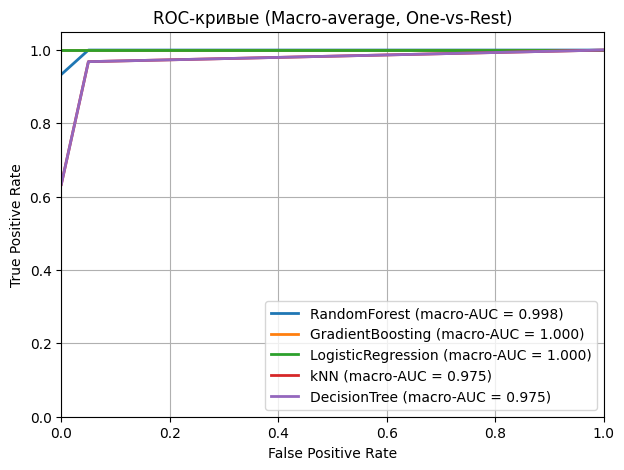

In [14]:
classes = y.unique()
y_test_bin = label_binarize(y_test, classes=classes)
n_classes = y_test_bin.shape[1]

plt.figure(figsize=(7, 5))

for name, model in all_models.items():
    y_score = model.predict_proba(X_test)

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= n_classes

    macro_auc = auc(all_fpr, mean_tpr)
    plt.plot(all_fpr, mean_tpr, label=f'{name} (macro-AUC = {macro_auc:.3f})', lw=2)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые (Macro-average, One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [16]:
best_ensemble = rf
best_baseline = baselines['LogisticRegression']

for name, model in [('Random Forest (лучший ансамбль)', best_ensemble),
                    ('Logistic Regression (лучший бейзлайн)', best_baseline)]:

    cv_scores = cross_validate(
        model, X, y, cv=5,
        scoring=('accuracy', 'f1_macro', 'roc_auc_ovr')
    )

    print(f"\n{name}:")
    print(f"  Accuracy CV: {cv_scores['test_accuracy'].mean():.4f} ± {cv_scores['test_accuracy'].std():.4f}")
    print(f"  F1 macro CV: {cv_scores['test_f1_macro'].mean():.4f} ± {cv_scores['test_f1_macro'].std():.4f}")
    print(f"  ROC-AUC OVR CV: {cv_scores['test_roc_auc_ovr'].mean():.4f} ± {cv_scores['test_roc_auc_ovr'].std():.4f}")


Random Forest (лучший ансамбль):
  Accuracy CV: 0.9667 ± 0.0211
  F1 macro CV: 0.9665 ± 0.0213
  ROC-AUC OVR CV: 0.9923 ± 0.0094

Logistic Regression (лучший бейзлайн):
  Accuracy CV: 0.9733 ± 0.0249
  F1 macro CV: 0.9732 ± 0.0252
  ROC-AUC OVR CV: 0.9963 ± 0.0031
